# Deb Halder DX799 -Mod C1 Fall 2026 Dataset 2 (Web page Phishing Detection Dataset) 

https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset

### Web_page_dataset_phishing:

The dataset is available in https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset


This is a very good dataset and is highly usable for doing the phishing related EDA and we can build models to identify fraudulent /phishing websites based on the features provided

-The provided dataset includes 11430 URLs with 87 extracted features. The dataset is designed to be used as benchmarks for machine learning-based phishing detection systems. Features are from three different classes: 56 extracted from the structure and syntax of URLs, 24 extracted from the content of their correspondent pages, and 7 are extracted by querying external services. The dataset is balanced, it contains exactly 50% phishing and 50% legitimate URLs (information as available in Kaggle dataset page).

- This dataset has website and URL related data and this can work in conjunction with the email spam classification for phishing identification.  In the spam email we remove the URL parameters as it will cause noise. But we could indeitify URLs and then if there is an online data availabl;e which can be accessed which has URL related as given in this dataset it can provide us valuable information.

- Since this is all data about website  and ites domain there are no text body and thats the reason we will use the columns of data which are provided as features and do classification using SKLearn Linearmodel for regression

- I wll use regression with three different algorithms for linear regression with Lasso , Ridge and Elastic net regularization and compare performance and create confusion matrix to evaluate performance of it as classification engine. We will use 0.5  as the probabaility threshold so anything above 0.5 is considered 1 and any value less than equa to 0.5 will be marked as zero. We will also compare the RMAC and AUC besides confusion matrix to understand performance. I will also try to understnad the computation time for each . Since this is a big data set so compute time difference will be quickly identified  



#### Web Page Phishing Detection Code Execution Flow

#### 1: Environment Setup & Data Ingestion
- **Import Libraries**: Load required libraries including `pandas`, `numpy`, `matplotlib`, `seaborn`, `kagglehub`, `shutil`, and `pathlib`.
- **Fetch Dataset**: Download the dataset `shashwatwork/web-page-phishing-detection-dataset` via `kagglehub`.
- **Load Data**: Read `dataset_phishing.csv` into a Pandas DataFrame for processing.

#### 2: Data Exploration & Validation
- **Dimension Inspection**: Check initial dataframe shape (11,430 rows and 89 columns).
- **Type & Summary Check**: Execute `df.info()` to verify data types and `df.describe()` to inspect statistical distributions.
- **Data Quality Checks**:
   * Scan for missing values (`df.isnull().sum()`).
   * Identify and quantify duplicate rows.
-. **Target Class Audit**: Verify class balance in the `status` column (5,715 legitimate vs. 5,715 phishing records).

#### 3: Data Preprocessing & Cleaning
- **Label Encoding**: Convert target string values in `status` into binary integers (`1` for phishing, `0` for legitimate).
- **Stratified Sampling**: Extract a balanced sample of 10,000 rows to maintain equal class representations.
- **Feature Dropping**:
   * Drop the `url` column due to high cardinality (11,429 unique values).
   * Identify and remove zero-variance (constant) columns across all samples.

#### 4: Exploratory Data Analysis (EDA)
- **Univariate Analysis**: Plot stacked histograms and Kernel Density Estimation (KDE) curves for features partitioned by target class.
- **Correlation Matrix**: Calculate feature correlations and isolate pairs with correlation coefficients $\vert{}r\vert{} \ge 0.5$.
- **Feature Distribution Visualization**: Generate box plots and violin plots for key features, such as domain age and Google indexing status.

#### 5: Model Training & Regularization Code Flow

- **Train-Test Data Splitting**: The code utilizes `train_test_split` from `sklearn.model_selection` to randomly divide the dataset into training sets (for model learning) and testing sets (for unseen evaluation), typically using an 80/20 or 70/30 ratio. 
- **Feature Scaling**: Because regularized linear models calculate penalties based on feature weight sizes, the code applies `StandardScaler` or `MinMaxScaler` from `sklearn.preprocessing`. This ensures all features are on the same numerical scale, preventing features with larger inherent values from disproportionately influencing the regularization penalty.
- **Model Initialization**: The code instantiates the respective Scikit-Learn classes: `Ridge()`, `Lasso()`, and `ElasticNet()`. During initialization, the `alpha` hyperparameter is set to control the strictness of the regularization penalty.
- **Model Fitting**: The `.fit(X_train, y_train)` method is called on each model. The algorithm iteratively optimizes the internal feature weights, minimizing the loss function while applying the specific L1/L2 mathematical penalties to shrink insignificant feature weights.

#### 6: Thresholding & Model Evaluation Code Flow

- **Continuous Prediction Generation**: The code calls the `.predict(X_test)` method. Because Ridge, Lasso, and ElasticNet are inherently regression algorithms, they output continuous numerical values rather than discrete classes.
- **Binary Thresholding**: To adapt the regression output for classification, the code applies a mathematical threshold operation across the output array (e.g., `y_pred_binary = (y_pred_continuous > 0.5).astype(int)`). Values above 0.5 are converted to `1` (Phishing), and values 0.5 or below become `0` (Legitimate).
- **Metric Calculation**: The code leverages `sklearn.metrics` to score the thresholded predictions against the actual `y_test` labels:
   * **Confusion Matrix**: `confusion_matrix(y_test, y_pred_binary)` generates a 2x2 array detailing True Positives, True Negatives, False Positives, and False Negatives.
   * **RMSE**: `mean_squared_error(y_test, y_pred_continuous, squared=False)` calculates the root mean squared error to measure the variance of the raw prediction errors.
   * **ROC-AUC**: `roc_auc_score(y_test, y_pred_continuous)` maps the True Positive Rate against the False Positive Rate at various thresholds to measure overall class separation efficiency.
- **Execution Timing Benchmarking**: The code uses Python's `time` module (calling `time.time()` before and after the training/prediction blocks) to calculate and log the exact computational seconds required for each algorithm, allowing for a speed-versus-accuracy tradeoff comparison.


---

### References
1. **Dataset**: Web Page Phishing Detection Dataset (`shashwatwork/web-page-phishing-detection-dataset`), Kaggle.

#### Observation from this notebook:

Lower RMSE indicates better predictive performance.
Lasso has the lowest median RMSE, approximately 0.262.
Elastic Net is very close, with a median around 0.262–0.263.
Ridge has the highest median RMSE, approximately 0.263.
The differences between the models are very small—roughly 0.001 RMSE or less.
The boxplots overlap considerably, indicating that the models have similar performance across the validation folds.
The validation error ranges are also similar, approximately 0.253–0.266.
There do not appear to be major outliers or large instability differences among the models.

#### Overall conclusion
Based only on the cross-validation plot at the end:

Lasso appears to be the best model by a small margin, followed closely by Elastic Net. Ridge is marginally worse. However, the differences are small and the overlapping distributions suggest that no model is clearly superior based on RMSE alone for this dataset.

We also notice that Lasso dropped 9 coefficeints to 0 (as the non coefficeints are reduced to 72 instead of Ridge which haqs retained all and its at 81. Elastic net is in between the Ridge and Lasso)

We also notice that amount of time needed to do the fit for the elastic net is lowest for ridge followed by lass and then elastic net is the most time taken. So we will watch this going forward . Here the dataset was pretty small with only 11400 approx rows with 82 filtered columns(out of 88) and small text values.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os


### Let us import the data from kaggle and stage it in the local folder to process

In [78]:
from pathlib import Path
import shutil
import kagglehub

# Create the destination directory if it does not exist
destination_dir = Path("./dataset/phishing_website_dataset")
destination_dir.mkdir(parents=True, exist_ok=True)

# Download the latest Kaggle dataset
download_path = Path(
    kagglehub.dataset_download(
        "shashwatwork/web-page-phishing-detection-dataset"
    )
)

print("KaggleHub download directory:")
print(download_path)

# Find downloaded files
downloaded_files = [
    file_path
    for file_path in download_path.rglob("*")
    if file_path.is_file()
]

if not downloaded_files:
    raise FileNotFoundError(
        f"No files found in the Kaggle download directory: {download_path}"
    )

# Copy downloaded files into the project directory
for source_file in downloaded_files:
    destination_file = destination_dir / source_file.name
    shutil.copy2(source_file, destination_file)
    print(f"Saved: {destination_file}")

# Find the downloaded CSV file
csv_files = sorted(destination_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {destination_dir}"
    )

print("\nCSV files found:")
for csv_file in csv_files:
    print(csv_file.name)

# Load the first CSV file
website_csv = csv_files[0]
df_phishing_website_data = pd.read_csv(website_csv)

print("\nLoaded phishing website dataset:")
print(f"File: {website_csv}")
print(f"Shape: {df_phishing_website_data.shape}")

display(df_phishing_website_data.head())

# Delete only this dataset's KaggleHub cache directory
if download_path.exists() and download_path.is_dir():
    shutil.rmtree(download_path)
    print("\nDeleted KaggleHub cache directory:")
    print(download_path)
else:
    print("\nKaggleHub cache directory was not found:")
    print(download_path)

100%|██████████| 1.01M/1.01M [00:00<00:00, 4.50MB/s]

Extracting files...
KaggleHub download directory:
/Users/debasishhalder/.cache/kagglehub/datasets/shashwatwork/web-page-phishing-detection-dataset/versions/2
Saved: dataset/phishing_website_dataset/dataset_phishing.csv

CSV files found:
dataset_phishing.csv

Loaded phishing website dataset:
File: dataset/phishing_website_dataset/dataset_phishing.csv
Shape: (11430, 89)


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate



Deleted KaggleHub cache directory:
/Users/debasishhalder/.cache/kagglehub/datasets/shashwatwork/web-page-phishing-detection-dataset/versions/2


In [79]:
df_phishing_website_data.shape

(11430, 89)

In [80]:
df_phishing_website_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

#### Of the 88 columns we have two columns which are neither int or float ie status and url

In [81]:
df_phishing_website_data.describe()

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
count,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.0,11430.000000,...,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,1.143000e+04,11430.000000,11430.000000,11430.000000
mean,61.126684,21.090289,0.150569,2.480752,0.997550,0.022222,0.141207,0.162292,0.0,0.293176,...,0.124759,0.775853,0.439545,0.072878,492.532196,4062.543745,8.567566e+05,0.020122,0.533946,3.185739
std,55.297318,10.777171,0.357644,1.369686,2.087087,0.155500,0.364456,0.821337,0.0,0.998317,...,0.330460,0.417038,0.496353,0.259948,814.769415,3107.784600,1.995606e+06,0.140425,0.498868,2.536955
min,12.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,-1.000000,-12.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,33.000000,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,84.000000,972.250000,0.000000e+00,0.000000,0.000000,1.000000
50%,47.000000,19.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,242.000000,3993.000000,1.651000e+03,0.000000,1.000000,3.000000
75%,71.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,1.000000,0.000000,449.000000,7026.750000,3.738455e+05,0.000000,1.000000,5.000000
max,1641.000000,214.000000,1.000000,24.000000,43.000000,4.000000,3.000000,19.000000,0.0,19.000000,...,1.000000,1.000000,1.000000,1.000000,29829.000000,12874.000000,1.076799e+07,1.000000,1.000000,10.000000


In [82]:
#lets us check for null values
df_phishing_website_data.isnull().sum()

url                0
length_url         0
length_hostname    0
ip                 0
nb_dots            0
                  ..
web_traffic        0
dns_record         0
google_index       0
page_rank          0
status             0
Length: 89, dtype: int64

In [83]:
# let us check if there are any rows with null values
df_phishing_website_data[df_phishing_website_data.isnull().any(axis=1)]


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status


#### There are no rows with null values

In [84]:
#check if there are duplicate rows
df_phishing_website_data.duplicated().sum()

0

#### There are no duplicate rows

In [85]:
#lets check how many unique values are there in status
df_phishing_website_data['status'].nunique()



2

In [86]:
df_phishing_website_data['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

### The dataset is balanced dataset with equal number of legitimate and phishing site information

In [47]:
#let us change the dtype of status to int where 0 is 'legitimate' and 1 is 'phishing'
df_phishing_website_data['status'] = df_phishing_website_data['status'].apply(lambda x: 1 if x.split()[0] == 'phishing' else 0)
df_phishing_website_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [48]:
#lets check count of unique values in url
df_phishing_website_data['url'].unique().shape

(11429,)

In [49]:
# Create a random sample of 1000 rows while maintaining class balance
def create_balanced_sample(df, sample_size=500, random_state=42):
    # calculate the number of samples needed from each class
    samples_per_class = sample_size // 2

    # split the data by class
    spam = df[df['status'] == 1]
    non_spam = df[df['status'] == 0]

    # sample equally from each class
    spam_sample = spam.sample(n=samples_per_class, random_state=random_state)
    non_spam_sample = non_spam.sample(n=samples_per_class, random_state=random_state)

    # combine the samples
    balanced_sample = pd.concat([spam_sample, non_spam_sample])

    # chuffle the combined sample
    balanced_sample = balanced_sample.sample(frac=1, random_state=random_state).reset_index(drop=True)

    return balanced_sample

# create the balanced sample
sampled_df = create_balanced_sample(df_phishing_website_data, sample_size= 10000, random_state=39)

# verify the sample
print("Original dataset shape:", df_phishing_website_data.shape)
print("Sampled dataset shape:", sampled_df.shape)
print("\nClass distribution in sample:")
print(sampled_df['status'].value_counts())

# run the analysis on the sampled data
#analyze_phishing_data(sampled_df)

Original dataset shape: (11430, 89)
Sampled dataset shape: (10000, 89)

Class distribution in sample:
status
0    5000
1    5000
Name: count, dtype: int64


### we will not use the URL info as it looks to be unique URL and we see total 11429 unique urls


In [50]:
# lets take the sampled df and drop the url column
sampled_df=sampled_df.drop(columns=['url'])

In [51]:
#This function removes columns whose values are the same in every row.
def remove_constant_columns(df):
    return df.loc[:, (df != df.iloc[0]).any()]

def perform_univariate_analysis(df):
    # calculate number of rows and columns for subplots
    n_features = len(df.columns)
    n_cols = 2
    n_rows = (n_features + n_cols - 1) // n_cols

    # create figure with subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3*n_rows))
    fig.suptitle('Univariate Analysis of Features', fontsize=16, y=1.02)

    # flatten axes array for easier iteration
    axes = axes.flatten()

    # create histograms and KDE plots for each feature
    for idx, column in enumerate(df.columns):
        # Histogram with KDE
        sns.histplot(data=df, x=column, hue='status', multiple="stack", kde=True, ax=axes[idx])
        axes[idx].set_title(f'Distribution of {column}')
        axes[idx].set_xlabel(column)
        axes[idx].set_ylabel('Count')

    # remove empty subplots if any
    for idx in range(len(df.columns), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [52]:
# Method to do bivariate analysis

def perform_bivariate_analysis(df):
      # create correlation Matrix
    plt.figure(figsize=(8, 6))
    correlation_matrix = df.corr()
    sns.heatmap(correlation_matrix,
                annot=True,
                cmap='magma',
                center=0,
                fmt='.2f',
                square=True)
    plt.title('Correlation Matrix of Features')
    plt.tight_layout()
    plt.show()

    significant_correlations = create_correlation_df(correlation_matrix, threshold=0.5)
    print("Significant Correlation values : ", significant_correlations)

    # pairplot with KDE
    #print("generating pairplot ...")
    #sns.pairplot(df, hue='status', diag_kind='kde')
    #plt.show()

    # violin plots
    features = [col for col in df.columns if col != 'status']
    n_features = len(features)
    n_cols = 2
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3*n_rows))
    fig.suptitle('Violin Plots by Status', fontsize=16, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.violinplot(data=df, x='status', y=feature, ax=axes[idx])
        axes[idx].set_title(f'{feature} by Status')

    # remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

    # generate box plots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6*n_rows))
    fig.suptitle('Box Plots by Status', fontsize=16, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.boxplot(data=df, x='status', y=feature, ax=axes[idx])
        axes[idx].set_title(f'{feature} by Status')

    # Remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [53]:
def perform_kde_analysis(df):
    features = [col for col in df.columns if col != 'status']
    n_features = len(features)
    n_cols = 2
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 3*n_rows))
    fig.suptitle('KDE Plots by Feature', fontsize=16, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.kdeplot(data=df, x=feature, hue='status', ax=axes[idx])
        axes[idx].set_title(f'KDE Plot of {feature}')

    # Remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [54]:
def analyze_phishing_data(df):
	#execute it in the below sequence
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df)
	#print("\nPerforming Bivariate Analysis...")
	#perform_bivariate_analysis(df)
	#print("\nPerforming KDE Analysis...")
	#perform_kde_analysis(df)

In [55]:
def analyze_phishing_web_Univariate_data(df):
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df)


In [56]:
def analyze_phishing_web_Bivariate_data(df):
	print("\nPerforming Bivariate Analysis...")
	perform_bivariate_analysis(df)
	print("\nPerforming KDE Analysis...")
	perform_kde_analysis(df)

In [57]:
def create_correlation_df(correlation_matrix, threshold=0.5):

    #  creates a DataFrame of significant correlations.

    correlations = []

    for i in range(len(correlation_matrix.columns)):
        for j in range(i + 1, len(correlation_matrix.columns)):
            corr_value = correlation_matrix.iloc[i, j]
            if abs(corr_value) >= threshold:
                correlations.append({
                    'Feature 1': correlation_matrix.columns[i],
                    'Feature 2': correlation_matrix.columns[j],
                    'Correlation': corr_value
                })

    corr_df = pd.DataFrame(correlations)
    return corr_df.sort_values('Correlation', key=abs, ascending=False)


In [58]:
df_phishing_web_cleaned = remove_constant_columns(sampled_df)

### Lets do some preliminary univariate analysis which may show us some interesting facts abou the URL's for phishing:

- We will not do Bivariate analysis as we have good understanding abou tthe data through code is there in this notebook as its part of my standard template
- Domain age is shorter
- Google index are mostly zero (i.e non indexed and thereare few more)

Performing Univariate Analysis...




In [59]:
df_phishing_web_cleaned = remove_constant_columns(sampled_df)
analyze_phishing_data(df_phishing_web_cleaned)

In [ ]:
# We will not analyze the bivariate relationships in the cleaned phishing web data skipping this as we want to do regression analysis with lasso socommenting the next line of code
# analyze_phishing_web_Bivariate_data(df_phishing_web_cleaned)

### module799


In [61]:
#Lets now implement the regression code to predict the status of the website using Ridge, Lasso, and Elastic Net regression models

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

random_key = 42

# Work with a copy of the original data
reg_data = df_phishing_website_data.copy()

# Confirm that the target column exists
if "status" not in reg_data.columns:
    raise ValueError(
        f"The target column 'status' was not found. "
        f"Available columns are: {reg_data.columns.tolist()}"
    )

# Remove rows with missing target values
reg_data = reg_data.dropna(subset=["status"]).copy()

# Convert the binary target to integers
y = reg_data["status"].astype(int)

# Confirm that status contains only binary values
if not y.isin([0, 1]).all():
    raise ValueError(
        f"The status column must contain only 0 and 1. "
        f"Found values: {sorted(y.unique())}"
    )

# Keep only numeric predictors.
# Raw text columns such as URL strings cannot be used directly by
# SimpleImputer(strategy='median'), StandardScaler, Ridge, Lasso, or Elastic Net.
non_numeric_columns = (
    reg_data.drop(columns=["status"])
    .select_dtypes(exclude=np.number)
    .columns.tolist()
)

X = (
    reg_data.drop(columns=["status"])
    .select_dtypes(include=np.number)
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

if X.shape[1] == 0:
    raise ValueError("No numeric predictor columns were found.")

print("Non-numeric columns excluded:")
print(non_numeric_columns)

print("\nNumeric predictors used:")
print(X.columns.tolist())

print("\nTarget data type:", y.dtype)
print("Target values:", sorted(y.unique()))
print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nPredictor matrix shape:", X.shape)
print("Target shape:", y.shape)

# Split the data while preserving the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=random_key,
    stratify=y,
)

# Preprocessing for numeric predictors
preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance_filter", VarianceThreshold()),
    ("scaler", StandardScaler()),
])

# Required regression models
models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(
        alpha=0.001,
        max_iter=50_000,
    ),
    "Elastic Net": ElasticNet(
        alpha=0.001,
        l1_ratio=0.5,
        max_iter=50_000,
    ),
}

results = []
fitted_models = {}
continuous_predictions = {}
class_predictions = {}

for model_name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", model),
    ])

    # Fit the model using only the training data
    pipeline.fit(X_train, y_train)

    # Regression models produce continuous scores
    scores = pipeline.predict(X_test)

    # Keep scores between 0 and 1 for easier interpretation
    scores_clipped = np.clip(scores, 0, 1)

    # Convert continuous scores to binary predictions
    predictions = (scores_clipped >= 0.5).astype(int)

    fitted_models[model_name] = pipeline
    continuous_predictions[model_name] = scores_clipped
    class_predictions[model_name] = predictions

    results.append({
        "model": model_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_test, scores_clipped)
        ),
        "R2": r2_score(y_test, scores_clipped),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0,
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0,
        ),
    })

# Display results for all three regression models
results_df = (
    pd.DataFrame(results)
    .sort_values(
        by=["F1", "Precision"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(results_df)

Non-numeric columns excluded:
['url']

Numeric predictors used:
['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_

,model,RMSE,R2,Accuracy,Precision,Recall,F1
0,Ridge,0.259388,0.730871,0.912511,0.903336,0.923885,0.913495
1,Elastic Net,0.259785,0.730048,0.912511,0.903336,0.923885,0.913495
2,Lasso,0.260200,0.729183,0.912511,0.904027,0.923010,0.913420


In [69]:
import ipywidgets as widgets
# Provides interactive notebook controls ... RadioButtons.

from IPython.display import clear_output, display
# Provides functions to display widgets and refresh output.


from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

RANDOM_KEY = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
CLASSIFICATION_THRESHOLD = 0.5

MODEL_COLORS = {
    "Ridge": "blue",
    "Lasso": "red",
    "Elastic Net": "green",
}


# ------------------------------------------------------------
# Data preparation
# ------------------------------------------------------------

def prepare_regression_data(dataframe, target_column="status"):
    """Validate prepared data and return numeric X and binary y."""
    reg_data = dataframe.copy()

    if target_column not in reg_data.columns:
        raise ValueError(
            f"Missing target column: {target_column}"
        )

    if reg_data[target_column].isna().any():
        raise ValueError(
            f"Missing values found in {target_column}"
        )

    y = reg_data[target_column].astype(int)

    if not y.isin([0, 1]).all():
        raise ValueError(
            f"{target_column} must contain only 0 and 1. "
            f"Found: {sorted(y.unique())}"
        )

    X = reg_data.drop(columns=[target_column])

    # Raw URLs are text and cannot be passed directly to
    # Ridge, Lasso, or Elastic Net.
    non_numeric_columns = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        print(
            "Non-numeric columns excluded from regression:",
            non_numeric_columns,
        )

        X = X.drop(
            columns=non_numeric_columns
        )

    if X.empty:
        raise ValueError(
            "No numeric predictor columns remain after removing "
            "non-numeric columns."
        )

    # Convert infinite values to missing values so the pipeline's
    # median imputer can process them.
    X = X.replace(
        [np.inf, -np.inf],
        np.nan,
    )

    if not np.isfinite(
        X.notna().to_numpy()
    ).all():
        raise ValueError(
            "Unexpected invalid predictor values remain."
        )

    print("Numeric predictors used:")
    print(X.columns.tolist())

    return X, y

In [ ]:
# Create helper method to split the data into training and testing sets while preserving class proportions.

def split_regression_data(X, y, random_key=RANDOM_KEY):
    """Create stratified training and testing sets."""
    return train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=random_key,
        stratify=y,
    )


# ------------------------------------------------------------
# Model setup
# ------------------------------------------------------------

def create_preprocessing_pipeline():
    """Create preprocessing for numeric predictor columns."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance_filter", VarianceThreshold()),
        ("scaler", StandardScaler()),
    ])


def create_models():
    """Return the required Ridge, Lasso, and Elastic Net models."""
    return {
        "Ridge": Ridge(alpha=1.0),
        "Lasso": Lasso(
            alpha=0.001,
            max_iter=50_000,
        ),
        "Elastic Net": ElasticNet(
            alpha=0.001,
            l1_ratio=0.5,
            max_iter=50_000,
        ),
    }


def create_model_pipeline(model):
    """Combine preprocessing and a regression model."""
    return Pipeline([
        ("preprocessing", create_preprocessing_pipeline()),
        ("model", model),
    ])



In [ ]:
# ------------------------------------------------------------
# Method to evaluate a model metrics scores and params
# ------------------------------------------------------------

def calculate_model_metrics(
    model_name,
    fitted_pipeline,
    X_test,
    y_test,
    cv_rmse,
):
    """Calculate test metrics and model diagnostics."""
    raw_scores = fitted_pipeline.predict(X_test)

    # Regression scores are treated as probability-like scores.
    scores = np.clip(raw_scores, 0, 1)

    predictions = (
        scores >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    fitted_model = fitted_pipeline.named_steps["model"]
    coefficients = np.asarray(
        fitted_model.coef_
    ).ravel()

    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1],
    )

    auc_value = roc_auc_score(
        y_test,
        scores,
    )

    metrics = {
        "Model": model_name,
        "Estimator": type(fitted_model).__name__,
        "Alpha": float(fitted_model.alpha),
        "L1_Ratio": getattr(
            fitted_model,
            "l1_ratio",
            np.nan,
        ),
        "Nonzero_Coefficients": int(
            np.sum(np.abs(coefficients) > 1e-8)
        ),
        "Total_Coefficients": len(coefficients),
        "CV_RMSE_Mean": cv_rmse.mean(),
        "CV_RMSE_Std": cv_rmse.std(),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, scores)
        ),
        "R2": r2_score(y_test, scores),
        "Accuracy": accuracy_score(
            y_test,
            predictions,
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0,
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0,
        ),
        "AUC": auc_value,
        "True_Negatives": matrix[0, 0],
        "False_Positives": matrix[0, 1],
        "False_Negatives": matrix[1, 0],
        "True_Positives": matrix[1, 1],
    }

    return {
        "metrics": metrics,
        "raw_scores": raw_scores,
        "scores": scores,
        "predictions": predictions,
        "confusion_matrix": matrix,
    }


In [ ]:
# Create function to run each of the three regression models and evaluate them using cross-validation and test metrics.

import time

def evaluate_models(models, X_train, X_test, y_train, y_test):
    results = []
    fitted_models = {}
    continuous_predictions = {}
    class_predictions = {}
    confusion_matrices = {}
    cv_errors = {}

    for model_name, model in models.items():
        pipeline = create_model_pipeline(model)

        # Time cross-validation
        cv_start = time.perf_counter()

        cv_mse = -cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=CV_FOLDS,
            scoring="neg_mean_squared_error",
            n_jobs=-1,
        )

        cv_time_seconds = time.perf_counter() - cv_start
        cv_rmse = np.sqrt(cv_mse)
        cv_errors[model_name] = cv_rmse

        # Time final fit
        fit_start = time.perf_counter()

        pipeline.fit(
            X_train,
            y_train,
        )

        fit_time_seconds = time.perf_counter() - fit_start

        # Time test prediction
        predict_start = time.perf_counter()

        evaluation = calculate_model_metrics(
            model_name,
            pipeline,
            X_test,
            y_test,
            cv_rmse,
        )

        predict_time_seconds = time.perf_counter() - predict_start

        evaluation["metrics"]["CV_Time_Seconds"] = cv_time_seconds
        evaluation["metrics"]["Fit_Time_Seconds"] = fit_time_seconds
        evaluation["metrics"]["Prediction_Time_Seconds"] = (
            predict_time_seconds
        )
        evaluation["metrics"]["Total_Model_Time_Seconds"] = (
            cv_time_seconds
            + fit_time_seconds
            + predict_time_seconds
        )

        fitted_models[model_name] = pipeline
        continuous_predictions[model_name] = evaluation["scores"]
        class_predictions[model_name] = evaluation["predictions"]
        confusion_matrices[model_name] = evaluation["confusion_matrix"]

        results.append(evaluation["metrics"])

    results_df = (
        pd.DataFrame(results)
        .sort_values(
            by=["F1", "Precision"],
            ascending=False,
        )
        .reset_index(drop=True)
    )

    return {
        "results_df": results_df,
        "fitted_models": fitted_models,
        "continuous_predictions": continuous_predictions,
        "class_predictions": class_predictions,
        "confusion_matrices": confusion_matrices,
        "cv_errors": cv_errors,
    }


In [74]:

# ------------------------------------------------------------
# Confusion-matrix plot
# ------------------------------------------------------------

def plot_confusion_matrices(
    confusion_matrices,
    display_labels=("Legitimate (0)", "Phishing (1)"),
):
    """Plot one confusion matrix for each model."""
    model_names = list(confusion_matrices.keys())

    fig, axes = plt.subplots(
        1,
        len(model_names),
        figsize=(15, 4),
        squeeze=False,
    )

    axes = axes.ravel()

    for position, model_name in enumerate(model_names):
        display_object = ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrices[model_name],
            display_labels=display_labels,
        )

        display_object.plot(
            ax=axes[position],
            cmap="Blues",
            colorbar=False,
            values_format="d",
        )

        axes[position].set_title(model_name)

    fig.suptitle(
        "Confusion Matrices",
        fontsize=14,
    )

    fig.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Interactive ROC plot
# ------------------------------------------------------------

def create_interactive_roc_plot(
    continuous_predictions,
    y_test,
    model_colors=MODEL_COLORS,
):
    """Create radio buttons for selecting and plotting one ROC curve."""
    model_names = list(continuous_predictions.keys())

    model_selector = widgets.RadioButtons(
        options=model_names,
        value=model_names[0],
        description="Model:",
    )

    roc_output = widgets.Output()

    def plot_selected_roc(model_name):
        with roc_output:
            clear_output(wait=True)

            scores = continuous_predictions[model_name]

            false_positive_rate, true_positive_rate, _ = roc_curve(
                y_test,
                scores,
            )

            auc_value = roc_auc_score(
                y_test,
                scores,
            )

            fig, ax = plt.subplots(
                figsize=(8, 6)
            )

            ax.plot(
                false_positive_rate,
                true_positive_rate,
                color=model_colors.get(
                    model_name,
                    "purple",
                ),
                linewidth=2.5,
                label=f"{model_name} "
                      f"(AUC = {auc_value:.6f})",
            )

            ax.plot(
                [0, 1],
                [0, 1],
                linestyle="--",
                color="gray",
                label="Random classifier",
            )

            ax.set_title(
                f"ROC Curve: {model_name}"
            )
            ax.set_xlabel("False Positive Rate")
            ax.set_ylabel("True Positive Rate")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.05)
            ax.grid(alpha=0.3)
            ax.legend(loc="lower right")

            fig.tight_layout()
            display(fig)
            plt.close(fig)

    def on_model_change(change):
        if change["name"] == "value":
            plot_selected_roc(change["new"])

    model_selector.observe(
        on_model_change,
        names="value",
    )

    display(
        model_selector,
        roc_output,
    )

    plot_selected_roc(
        model_selector.value
    )


# ------------------------------------------------------------
# Cross-validation error plot
# ------------------------------------------------------------

def plot_cross_validation_errors(cv_errors):
    """Plot the fold-level cross-validation RMSE for every model."""
    model_names = list(cv_errors.keys())

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.boxplot(
        [
            cv_errors[model_name]
            for model_name in model_names
        ],
        labels=model_names,
    )

    ax.set_title(
        "Cross-Validation RMSE by Model"
    )
    ax.set_xlabel("Regression model")
    ax.set_ylabel("RMSE")
    ax.grid(
        axis="y",
        alpha=0.3,
    )

    fig.tight_layout()
    plt.show()



Non-numeric columns excluded from regression: ['url']
Numeric predictors used:
['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyper

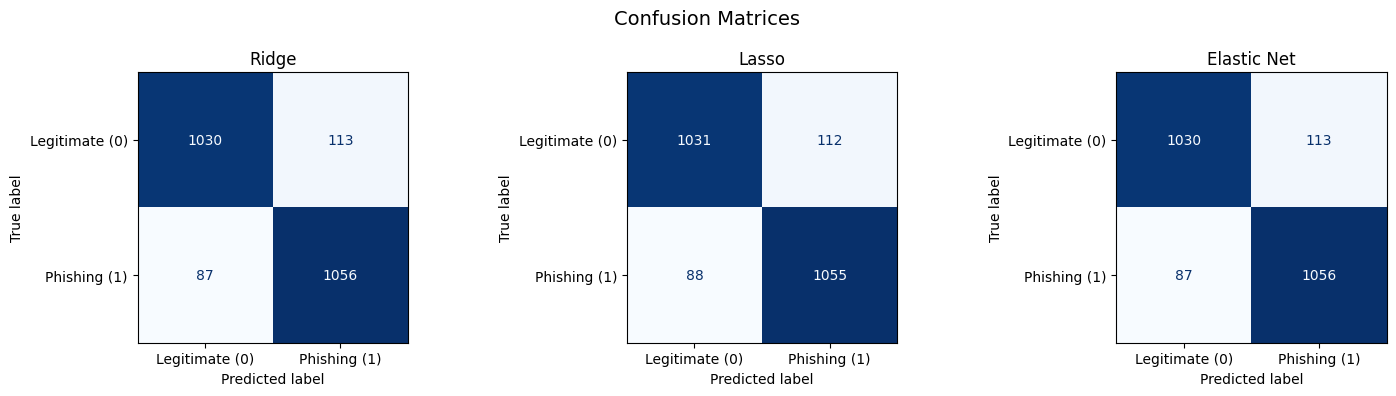

RadioButtons(description='Model:', options=('Ridge', 'Lasso', 'Elastic Net'), value='Ridge')

Output()

/var/folders/bm/9gklnwns2kxcypy3sp68vlc80000gn/T/ipykernel_67596/4261155952.py:150: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


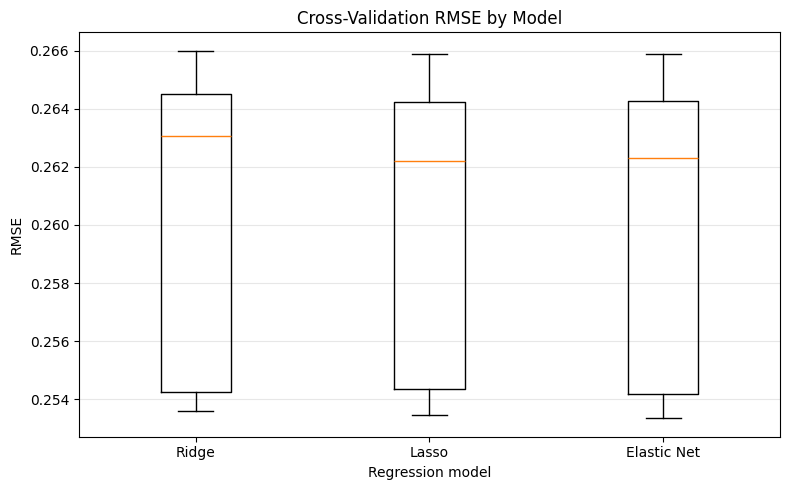

,Model,Estimator,Alpha,L1_Ratio,Nonzero_Coefficients,Total_Coefficients,CV_RMSE_Mean,CV_RMSE_Std,Test_RMSE,R2,...,F1,AUC,True_Negatives,False_Positives,False_Negatives,True_Positives,CV_Time_Seconds,Fit_Time_Seconds,Prediction_Time_Seconds,Total_Model_Time_Seconds
0,Ridge,Ridge,1.000,NaN,81,81,0.260283,0.005277,0.259388,0.730871,...,0.913495,0.973972,1030,113,87,1056,0.255936,0.074773,0.032235,0.362944
1,Elastic Net,ElasticNet,0.001,0.5,76,81,0.259999,0.005219,0.259785,0.730048,...,0.913495,0.973908,1030,113,87,1056,0.418850,0.140988,0.042182,0.602020
2,Lasso,Lasso,0.001,1.0,72,81,0.260035,0.005136,0.260200,0.729183,...,0.913420,0.974001,1031,112,88,1055,0.364577,0.083821,0.025338,0.473736


In [77]:
# ------------------------------------------------------------
# Run the workflow
# ------------------------------------------------------------

X, y = prepare_regression_data(
    df_phishing_website_data,
    target_column="status",
)

X_train, X_test, y_train, y_test = split_regression_data(
    X,
    y,
    random_key=RANDOM_KEY,
)

models = create_models()

evaluation = evaluate_models(
    models,
    X_train,
    X_test,
    y_train,
    y_test,
)

results_df = evaluation["results_df"]
fitted_models = evaluation["fitted_models"]
continuous_predictions = evaluation["continuous_predictions"]
class_predictions = evaluation["class_predictions"]
confusion_matrices = evaluation["confusion_matrices"]
cv_errors = evaluation["cv_errors"]

plot_confusion_matrices(
    confusion_matrices
)

create_interactive_roc_plot(
    continuous_predictions,
    y_test,
)

plot_cross_validation_errors(
    cv_errors
)

display(results_df)


The plot compares the cross-validation RMSE for Ridge, Lasso, and Elastic Net regression.

Lower RMSE indicates better predictive performance.
Lasso has the lowest median RMSE, approximately 0.262.
Elastic Net is very close, with a median around 0.262–0.263.
Ridge has the highest median RMSE, approximately 0.263.
The differences between the models are very small—roughly 0.001 RMSE or less.
The boxplots overlap considerably, indicating that the models have similar performance across the validation folds.
The validation error ranges are also similar, approximately 0.253–0.266.
There do not appear to be major outliers or large instability differences among the models.
Overall conclusion
Based only on this cross-validation plot:

Lasso appears to be the best model by a small margin, followed closely by Elastic Net. Ridge is marginally worse. However, the differences are small and the overlapping distributions suggest that no model is clearly superior based on RMSE alone.

We also notice that Lasso dropped 9 coefficeints to 0 (as the non coefficeints are reduced to 72 instead of Ridge which haqs retained all and its at 81. Elastic net is in between the Ridge and Lasso)

We also notice that amount of time needed to do the fit for the elastic net is lowest for ridge followed by lass and then elastic net is the most time taken. So we will watch this going forward . Here the dataset was pretty small with only 11400 approx rows with 82 filtered columns(out of 88) and small text values.

